In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset/Test/Black Sport/Black_Sport (1).jpg
/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset/Test/Black Sport/Black_Sport (10).jpg
/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset/Test/Black Sport/Black_Sport (11).jpg
/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset/Test/Black Sport/Black_Sport (12).jpg
/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset/Test/Black Sport/Black_Sport (13).jpg
/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset/Test/Black Sport/Black_Sport (14).jpg
/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset/Test/Black Sport/Black_Sport (15).jpg
/kaggle/input/

In [2]:
import os

dataset_path = "/kaggle/input/datasets/ashadullahhilgalib/rose-leaf-disease-dataset/Original_Rose_leaf_Disease_Dataset"

for folder in ["Train", "Test"]:
    print(folder)

    for class_name in os.listdir(os.path.join(dataset_path, folder)):
        class_path = os.path.join(dataset_path, folder, class_name)

        if os.path.isdir(class_path):
            print(class_name, ":", len(os.listdir(class_path)), "images")

Train
Black Spot : 268 images
Downy Mildew : 252 images
Dry Leaf : 571 images
Healthy Leaf : 534 images
Insect Hole : 342 images
Test
Black Sport : 67 images
Downy Mildew : 64 images
Dry Leaf : 141 images
Healthy Leaf : 134 images
Insect Hole : 85 images


In [3]:
import torch

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

PyTorch Version: 2.11.0+cpu
GPU Available: False


In [4]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

image_size = 128
batch_size = 16

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    os.path.join(dataset_path, "Train"),
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(dataset_path, "Test"),
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Classes:", train_dataset.classes)
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("Total Images:", len(train_dataset) + len(test_dataset))


Classes: ['Black Spot', 'Downy Mildew', 'Dry Leaf', 'Healthy Leaf', 'Insect Hole']
Training Images: 1967
Testing Images: 491
Total Images: 2458


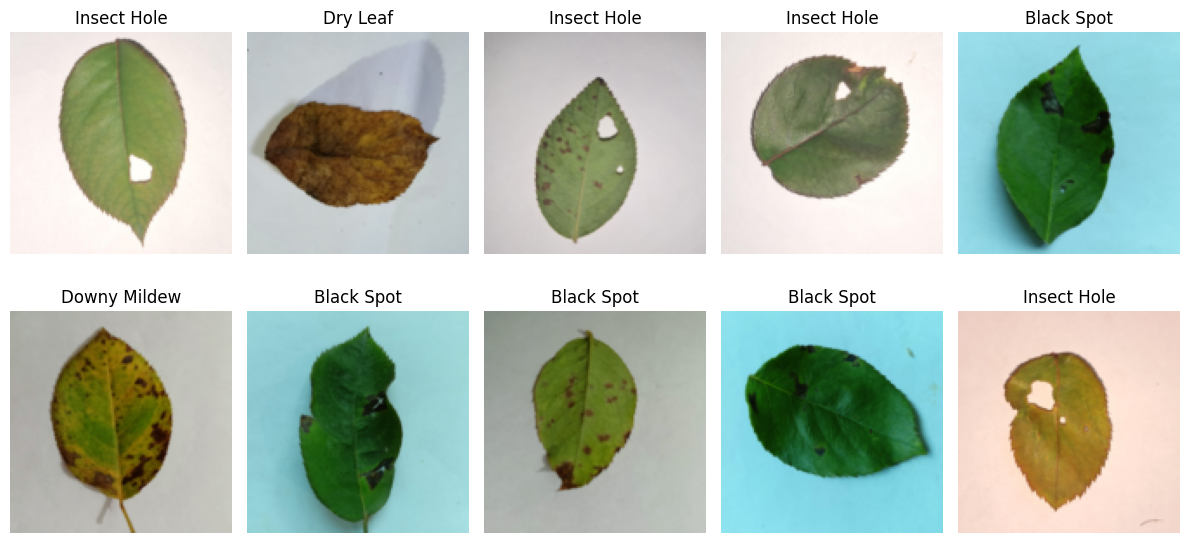

In [5]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = images[i].permute(1, 2, 0)

    plt.imshow(image)
    plt.title(train_dataset.classes[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RoseCNN(nn.Module):
    def __init__(self):
        super(RoseCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 64 * 16 * 16)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

model = RoseCNN()

print(model)

RoseCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=5, bias=True)
)


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Device:", device)
print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")

Device: cpu
Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001


In [8]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    accuracy = 100 * correct / total

    print("Epoch [{}/{}], Loss: {:.4f}, Accuracy: {:.2f}%".format(
        epoch + 1, num_epochs, epoch_loss, accuracy
    ))

Epoch [1/5], Loss: 1.0459, Accuracy: 54.65%
Epoch [2/5], Loss: 0.5383, Accuracy: 78.90%
Epoch [3/5], Loss: 0.3917, Accuracy: 84.34%
Epoch [4/5], Loss: 0.3821, Accuracy: 85.56%
Epoch [5/5], Loss: 0.2974, Accuracy: 88.87%


In [9]:
model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total
average_test_loss = test_loss / len(test_loader)

print("Test Loss: {:.4f}".format(average_test_loss))
print("Test Accuracy: {:.2f}%".format(test_accuracy))
print("Correct Predictions:", correct)
print("Total Test Images:", total)

Test Loss: 0.7450
Test Accuracy: 64.97%
Correct Predictions: 319
Total Test Images: 491


In [10]:
print("Model exists:", 'model' in globals())
print("Train Loader exists:", 'train_loader' in globals())
print("Test Loader exists:", 'test_loader' in globals())

Model exists: True
Train Loader exists: True
Test Loader exists: True


In [11]:
torch.save(model.state_dict(), "/kaggle/working/rose_cnn_model.pth")

print("Model saved successfully!")

Model saved successfully!


In [12]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes
))

Confusion Matrix:
[[ 35  28   0   2   2]
 [  2  60   2   0   0]
 [  0   2 137   2   0]
 [  1   0   0   4 129]
 [  0   0   0   2  83]]

Classification Report:
              precision    recall  f1-score   support

 Black Sport       0.92      0.52      0.67        67
Downy Mildew       0.67      0.94      0.78        64
    Dry Leaf       0.99      0.97      0.98       141
Healthy Leaf       0.40      0.03      0.06       134
 Insect Hole       0.39      0.98      0.56        85

    accuracy                           0.65       491
   macro avg       0.67      0.69      0.61       491
weighted avg       0.67      0.65      0.58       491



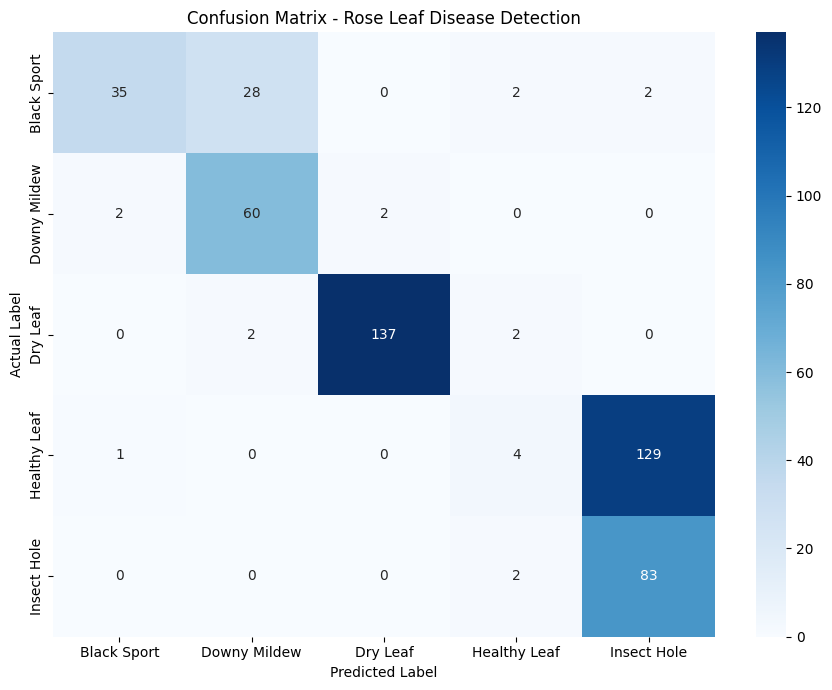

In [13]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Rose Leaf Disease Detection")

plt.tight_layout()
plt.show()

In [14]:
print("Class Names:")
print(test_dataset.classes)

print("\nClass to Index Mapping:")
print(test_dataset.class_to_idx)

print("\nConfusion Matrix Total:")
print(cm.sum())

print("\nCorrect Predictions:")
print(np.trace(cm))

Class Names:
['Black Sport', 'Downy Mildew', 'Dry Leaf', 'Healthy Leaf', 'Insect Hole']

Class to Index Mapping:
{'Black Sport': 0, 'Downy Mildew': 1, 'Dry Leaf': 2, 'Healthy Leaf': 3, 'Insect Hole': 4}

Confusion Matrix Total:
491

Correct Predictions:
319


In [15]:
print("Current Confusion Matrix:")
print(cm)

print("\nTotal Samples:", cm.sum())
print("Correct Predictions:", np.trace(cm))

accuracy = np.trace(cm) / cm.sum() * 100

print("Actual Accuracy: {:.2f}%".format(accuracy))

Current Confusion Matrix:
[[ 35  28   0   2   2]
 [  2  60   2   0   0]
 [  0   2 137   2   0]
 [  1   0   0   4 129]
 [  0   0   0   2  83]]

Total Samples: 491
Correct Predictions: 319
Actual Accuracy: 64.97%


In [16]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes
))

              precision    recall  f1-score   support

 Black Sport       0.92      0.52      0.67        67
Downy Mildew       0.67      0.94      0.78        64
    Dry Leaf       0.99      0.97      0.98       141
Healthy Leaf       0.40      0.03      0.06       134
 Insect Hole       0.39      0.98      0.56        85

    accuracy                           0.65       491
   macro avg       0.67      0.69      0.61       491
weighted avg       0.67      0.65      0.58       491



In [17]:
torch.save(model.state_dict(), "/kaggle/working/rose_cnn_model.pth")

print("Final Model Saved Successfully!")

Final Model Saved Successfully!


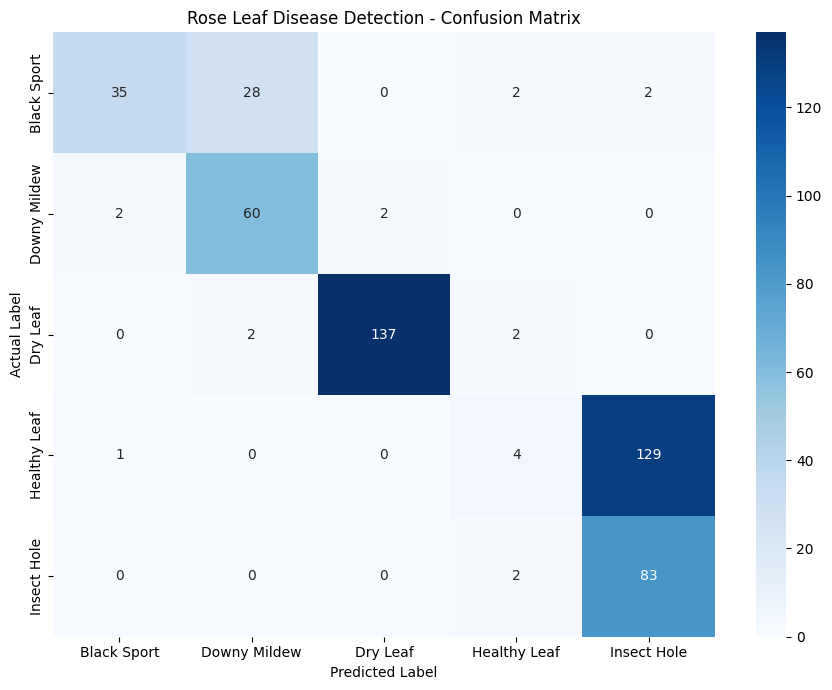

In [18]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Rose Leaf Disease Detection - Confusion Matrix")

plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png")
plt.show()

In [19]:
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    os.path.join(dataset_path, "Train"),
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(dataset_path, "Test"),
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Augmentation Updated Successfully!")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))

Augmentation Updated Successfully!
Training Images: 1967
Testing Images: 491


In [20]:
class RoseCNN(nn.Module):
    def __init__(self):
        super(RoseCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 64 * 16 * 16)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model = RoseCNN()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Improved CNN Model Created Successfully!")

Improved CNN Model Created Successfully!


In [21]:
num_epochs = 10

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print("Epoch [{}/{}], Loss: {:.4f}, Accuracy: {:.2f}%"
          .format(epoch + 1, num_epochs, epoch_loss, epoch_accuracy))

Epoch [1/10], Loss: 1.2672, Accuracy: 44.08%
Epoch [2/10], Loss: 0.8480, Accuracy: 64.87%
Epoch [3/10], Loss: 0.6655, Accuracy: 72.04%
Epoch [4/10], Loss: 0.6223, Accuracy: 75.50%
Epoch [5/10], Loss: 0.5202, Accuracy: 78.60%
Epoch [6/10], Loss: 0.5172, Accuracy: 79.16%
Epoch [7/10], Loss: 0.5577, Accuracy: 77.99%
Epoch [8/10], Loss: 0.4591, Accuracy: 80.33%
Epoch [9/10], Loss: 0.4452, Accuracy: 81.49%
Epoch [10/10], Loss: 0.4292, Accuracy: 83.43%


In [22]:
model.eval()

test_correct = 0
test_total = 0
test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
test_loss = test_loss / len(test_loader)

print("Test Loss: {:.4f}".format(test_loss))
print("Test Accuracy: {:.2f}%".format(test_accuracy))
print("Correct Predictions:", test_correct)
print("Total Test Images:", test_total)

Test Loss: 0.4443
Test Accuracy: 73.73%
Correct Predictions: 362
Total Test Images: 491


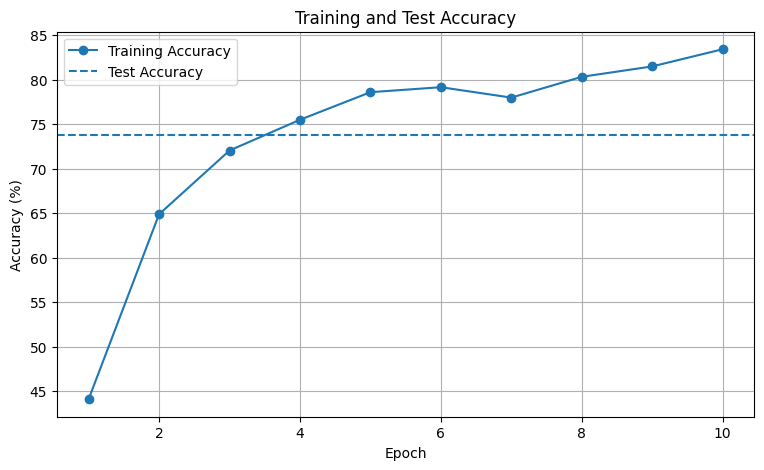

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), train_accuracies,
         marker='o', label='Training Accuracy')

plt.axhline(y=test_accuracy, linestyle='--',
            label='Test Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Test Accuracy")
plt.legend()
plt.grid()
plt.show()

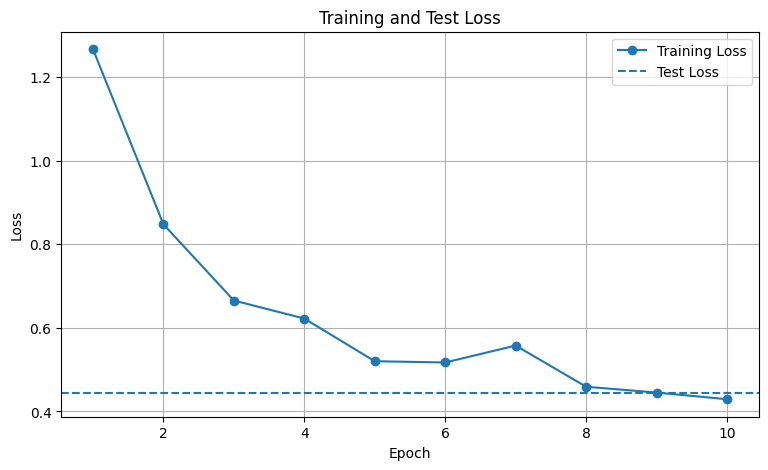

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), train_losses,
         marker='o', label='Training Loss')

plt.axhline(y=test_loss, linestyle='--',
            label='Test Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid()
plt.show()

In [25]:
model.eval()

correct_images = []
incorrect_images = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        for i in range(len(labels)):
            if predicted[i] == labels[i]:
                if len(correct_images) < 5:
                    correct_images.append(
                        (images[i].cpu(), labels[i].item(),
                         predicted[i].item())
                    )
            else:
                if len(incorrect_images) < 5:
                    incorrect_images.append(
                        (images[i].cpu(), labels[i].item(),
                         predicted[i].item())
                    )

        if len(correct_images) == 5 and len(incorrect_images) == 5:
            break

print("Correct Images:", len(correct_images))
print("Incorrect Images:", len(incorrect_images))

Correct Images: 5
Incorrect Images: 5


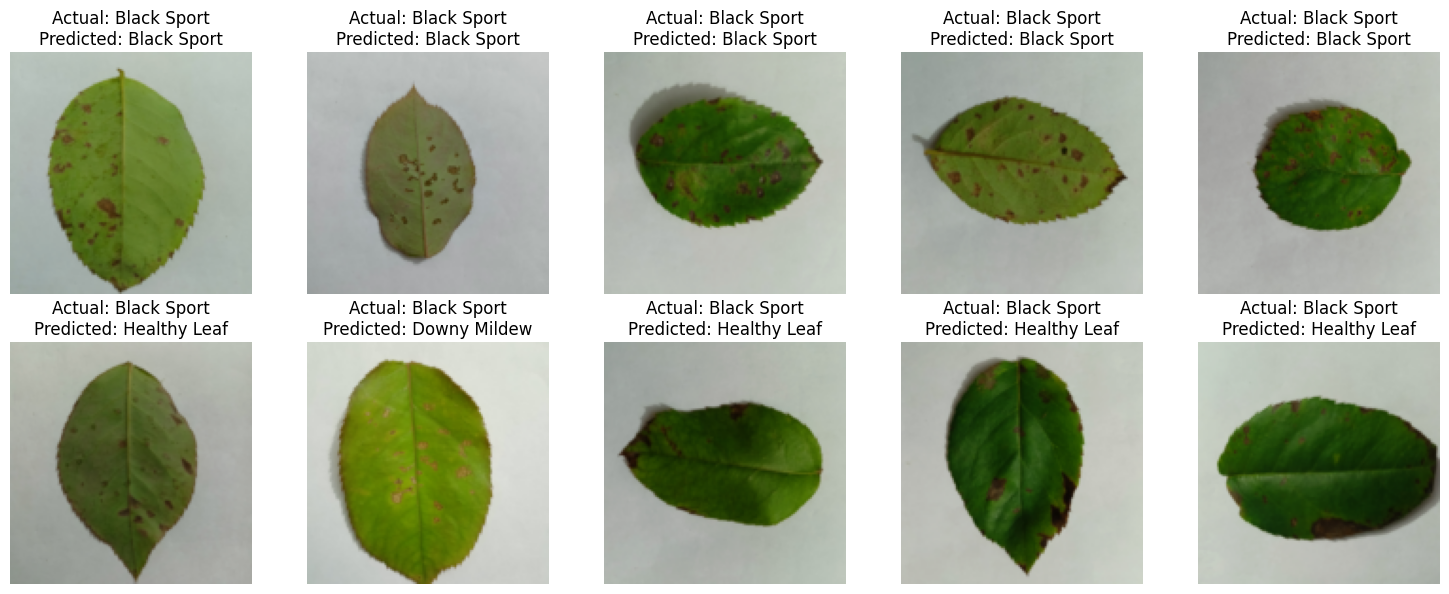

In [26]:
class_names = test_dataset.classes

plt.figure(figsize=(15, 6))

for i in range(5):
    image, actual, predicted = correct_images[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title("Actual: " + class_names[actual] +
              "\nPredicted: " + class_names[predicted])
    plt.axis("off")

for i in range(5):
    image, actual, predicted = incorrect_images[i]

    plt.subplot(2, 5, i + 6)
    plt.imshow(image.permute(1, 2, 0))
    plt.title("Actual: " + class_names[actual] +
              "\nPredicted: " + class_names[predicted])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
torch.save(model.state_dict(),
           "/kaggle/working/rose_cnn_model_improved.pth")

print("Final Model Saved Successfully!")

Final Model Saved Successfully!


In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

print("Total Images:", cm.sum())
print("Correct Predictions:", cm.trace())

Confusion Matrix:
[[ 60   3   0   4   0]
 [  4  58   2   0   0]
 [  0   0 139   2   0]
 [  1   0   0  35  98]
 [  2   0   0  13  70]]
Total Images: 491
Correct Predictions: 362


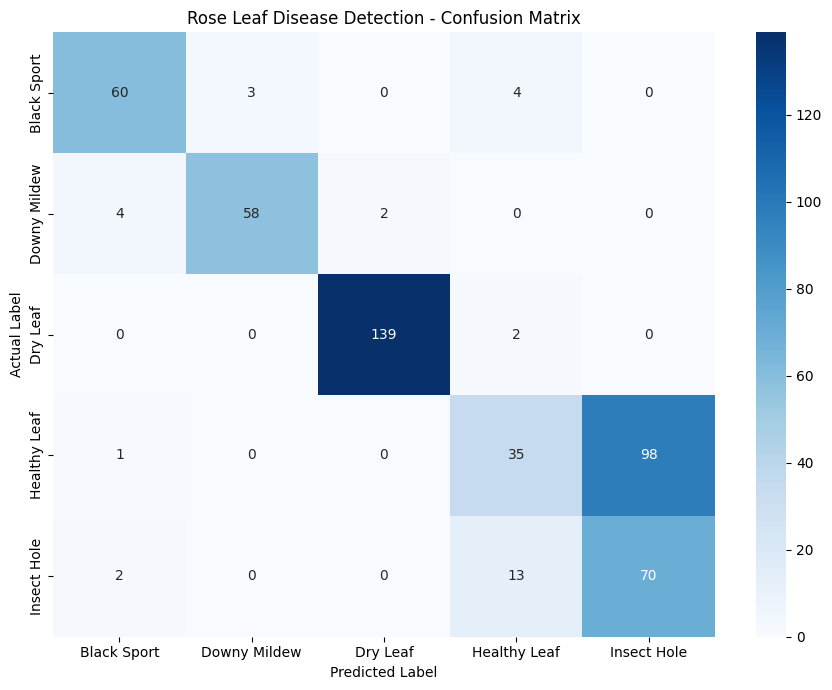

In [29]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Rose Leaf Disease Detection - Confusion Matrix")

plt.tight_layout()
plt.savefig("/kaggle/working/improved_confusion_matrix.png")
plt.show()

In [30]:
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes
)

print(report)

              precision    recall  f1-score   support

 Black Sport       0.90      0.90      0.90        67
Downy Mildew       0.95      0.91      0.93        64
    Dry Leaf       0.99      0.99      0.99       141
Healthy Leaf       0.65      0.26      0.37       134
 Insect Hole       0.42      0.82      0.55        85

    accuracy                           0.74       491
   macro avg       0.78      0.77      0.75       491
weighted avg       0.78      0.74      0.72       491



In [31]:
plt.savefig("/kaggle/working/final_confusion_matrix.png")

<Figure size 640x480 with 0 Axes>

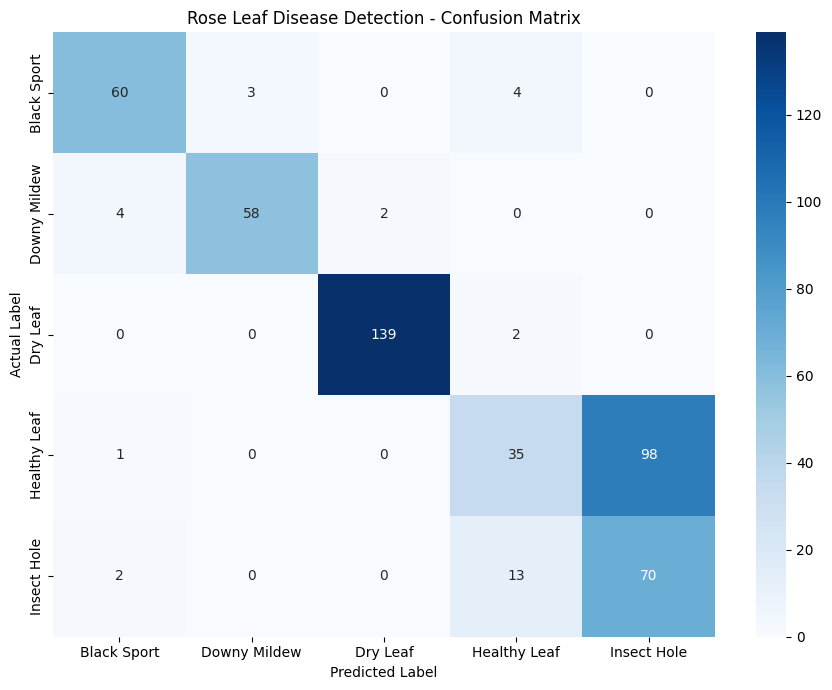

In [32]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Rose Leaf Disease Detection - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
plt.savefig("/kaggle/working/accuracy_graph.png",
            dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

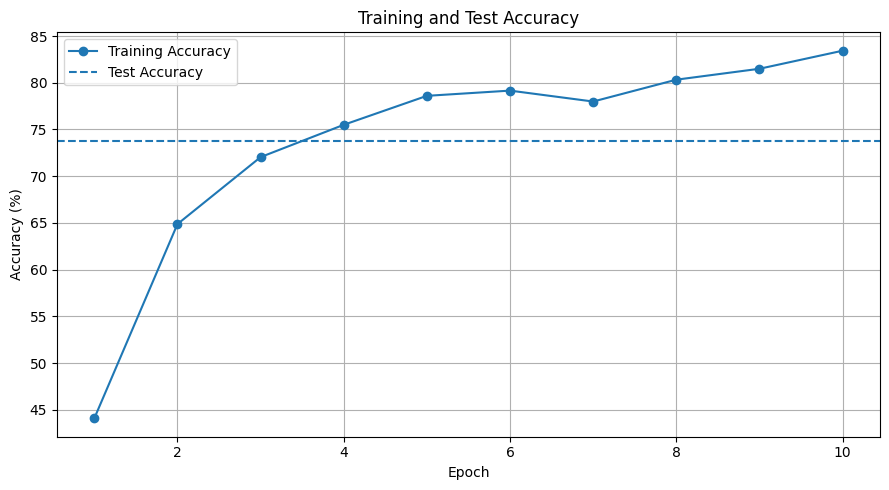

In [34]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), train_accuracies,
         marker='o', label='Training Accuracy')

plt.axhline(y=test_accuracy, linestyle='--',
            label='Test Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Test Accuracy")
plt.legend()
plt.grid()

plt.tight_layout()

plt.savefig("/kaggle/working/accuracy_graph.png",
            dpi=300, bbox_inches="tight")

plt.show()

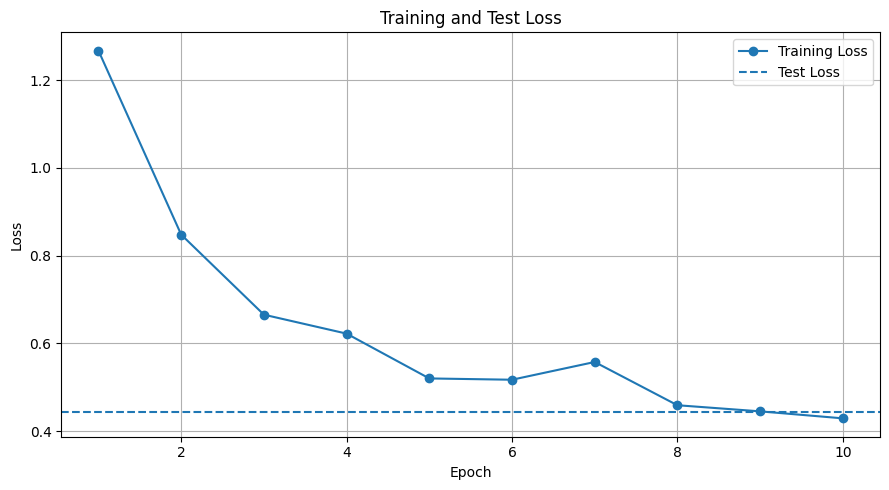

In [35]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), train_losses,
         marker='o', label='Training Loss')

plt.axhline(y=test_loss, linestyle='--',
            label='Test Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid()

plt.tight_layout()

plt.savefig("/kaggle/working/loss_graph.png",
            dpi=300, bbox_inches="tight")

plt.show()

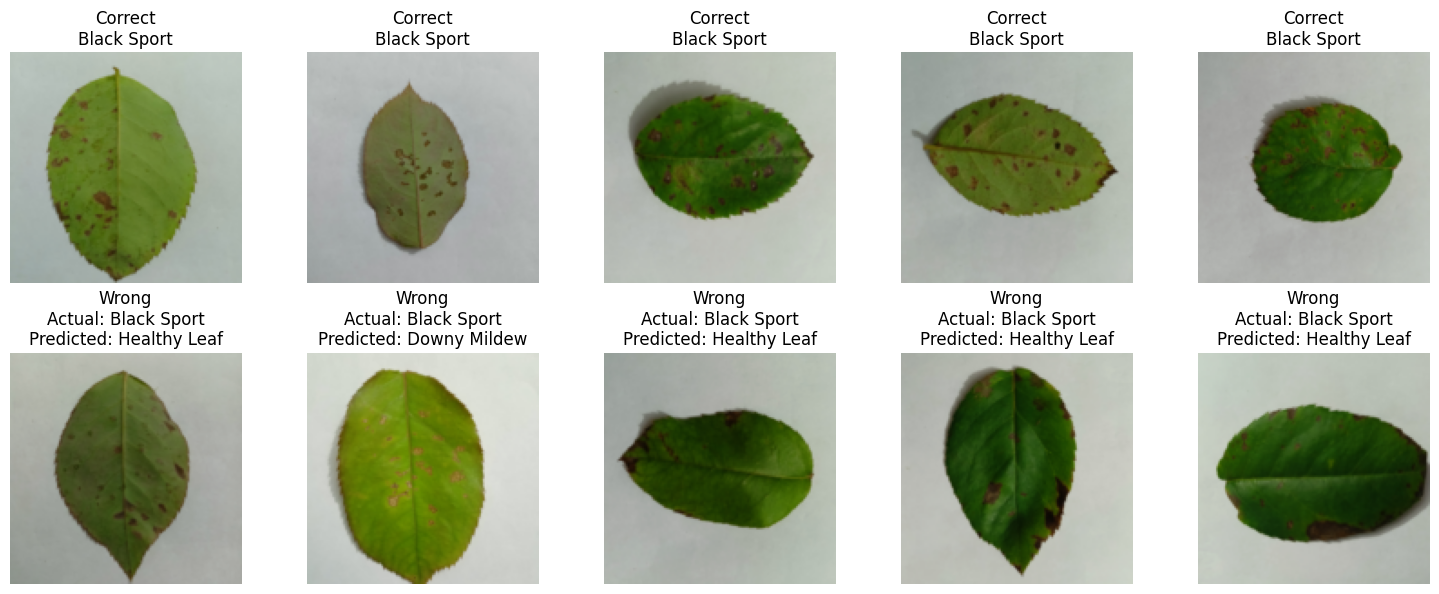

In [36]:
plt.figure(figsize=(15, 6))

for i in range(5):
    image, actual, predicted = correct_images[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title("Correct\n" + class_names[actual])
    plt.axis("off")

for i in range(5):
    image, actual, predicted = incorrect_images[i]

    plt.subplot(2, 5, i + 6)
    plt.imshow(image.permute(1, 2, 0))
    plt.title("Wrong\nActual: " + class_names[actual] +
              "\nPredicted: " + class_names[predicted])
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/prediction_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
torch.save(model.state_dict(), "/kaggle/working/rose_cnn_model_10_epoch.pth")
print("10 Epoch Model Saved Successfully!")

10 Epoch Model Saved Successfully!


In [38]:
num_epochs = 15

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(f"Epoch [{epoch+1}/15], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%")

Epoch [1/15], Loss: 0.4114, Accuracy: 83.22%
Epoch [2/15], Loss: 0.4263, Accuracy: 83.48%
Epoch [3/15], Loss: 0.3875, Accuracy: 83.78%
Epoch [4/15], Loss: 0.3781, Accuracy: 84.49%
Epoch [5/15], Loss: 0.4060, Accuracy: 83.22%
Epoch [6/15], Loss: 0.3842, Accuracy: 85.26%
Epoch [7/15], Loss: 0.3421, Accuracy: 86.02%
Epoch [8/15], Loss: 0.3903, Accuracy: 84.24%
Epoch [9/15], Loss: 0.3502, Accuracy: 86.63%
Epoch [10/15], Loss: 0.3610, Accuracy: 85.46%
Epoch [11/15], Loss: 0.3418, Accuracy: 86.78%
Epoch [12/15], Loss: 0.3440, Accuracy: 86.17%
Epoch [13/15], Loss: 0.3357, Accuracy: 85.97%
Epoch [14/15], Loss: 0.3079, Accuracy: 87.09%
Epoch [15/15], Loss: 0.3443, Accuracy: 86.32%


In [39]:
torch.save(model.state_dict(), "/kaggle/working/rose_cnn_model_25_epoch.pth")

print("25 Epoch Model Saved Successfully!")

25 Epoch Model Saved Successfully!


In [40]:
model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
average_loss = test_loss / len(test_loader)

print("Test Accuracy: {:.2f}%".format(accuracy))
print("Test Loss: {:.4f}".format(average_loss))
print("Correct Predictions:", correct)
print("Total Test Images:", total)

Test Accuracy: 78.82%
Test Loss: 0.4058
Correct Predictions: 387
Total Test Images: 491


In [41]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(all_labels, all_predictions,
                            target_names=test_dataset.classes))

Confusion Matrix:
[[ 44   0   0  23   0]
 [  3  59   2   0   0]
 [  0   0 140   1   0]
 [  0   0   0  70  64]
 [  0   0   0  11  74]]

Classification Report:
              precision    recall  f1-score   support

 Black Sport       0.94      0.66      0.77        67
Downy Mildew       1.00      0.92      0.96        64
    Dry Leaf       0.99      0.99      0.99       141
Healthy Leaf       0.67      0.52      0.59       134
 Insect Hole       0.54      0.87      0.66        85

    accuracy                           0.79       491
   macro avg       0.82      0.79      0.79       491
weighted avg       0.82      0.79      0.79       491



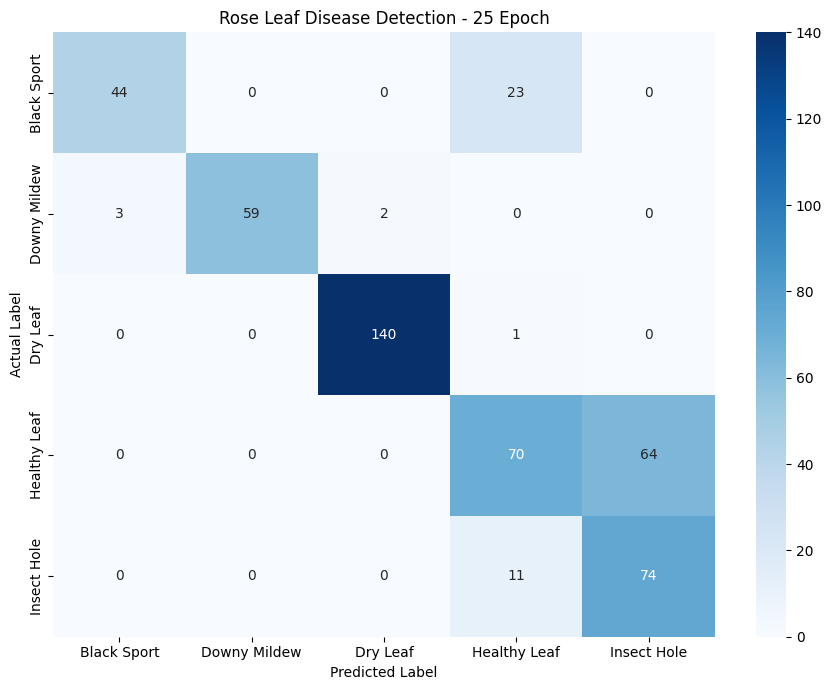

In [42]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Rose Leaf Disease Detection - 25 Epoch")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/25_epoch_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total Trainable Parameters:", total_params)

Total Trainable Parameters: 2121509
